In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [3]:
df = pd.read_csv('/content/imdb_top_100_cleaned.csv')

print("Dataset berhasil dibaca")

df.head()

Dataset berhasil dibaca


,rank,title,description,genre,rating,year
0,1,The Shawshank Redemption,Two imprisoned men bond over a number of years...,['Drama'],9.3,1994
1,2,The Godfather,The aging patriarch of an organized crime dyna...,"['Crime', 'Drama']",9.2,1972
2,3,The Dark Knight,When the menace known as the Joker wreaks havo...,"['Action', 'Crime', 'Drama']",9.0,2008
3,4,The Godfather Part II,The early life and career of Vito Corleone in ...,"['Crime', 'Drama']",9.0,1974
4,5,12 Angry Men,The jury in a New York City murder trial is fr...,"['Crime', 'Drama']",9.0,1957


In [4]:
# Melihat jumlah baris dan kolom
print("Ukuran dataset:", df.shape)

# Melihat nama kolom
print("\nNama kolom:")
print(df.columns)

# Memeriksa data kosong
print("\nData kosong:")
print(df.isnull().sum())

# Melihat informasi dataset
df.info()

Ukuran dataset: (100, 6)

Nama kolom:
Index(['rank', 'title', 'description', 'genre', 'rating', 'year'], dtype='object')

Data kosong:
rank           0
title          0
description    0
genre          0
rating         0
year           0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   rank         100 non-null    int64  
 1   title        100 non-null    object 
 2   description  100 non-null    object 
 3   genre        100 non-null    object 
 4   rating       100 non-null    float64
 5   year         100 non-null    int64  
dtypes: float64(1), int64(2), object(3)
memory usage: 4.8+ KB


In [5]:
data = df.copy()

# Mengambil variabel rating
x = data['rating'].values

# Menghitung jumlah sampel
n = len(x)

print("Jumlah sampel:", n)
print("\nData rating:")
print(x)

Jumlah sampel: 100

Data rating:
[9.3 9.2 9.  9.  9.  9.  9.  8.9 8.8 8.8 8.8 8.8 8.8 8.7 8.7 8.7 8.7 8.7
 8.7 8.6 8.6 8.6 8.6 8.6 8.6 8.6 8.6 8.6 8.6 8.6 8.6 8.6 8.6 8.5 8.5 8.5
 8.5 8.5 8.5 8.5 8.5 8.5 8.5 8.5 8.5 8.5 8.5 8.5 8.5 8.5 8.5 8.5 8.5 8.5
 8.5 8.4 8.4 8.4 8.4 8.4 8.4 8.4 8.4 8.4 8.4 8.4 8.4 8.4 8.4 8.4 8.4 8.4
 8.4 8.4 8.4 8.4 8.4 8.4 8.4 8.4 8.4 8.4 8.3 8.3 8.3 8.3 8.3 8.3 8.3 8.3
 8.3 8.3 8.3 8.3 8.3 8.3 8.3 8.3 8.3 8.3]


In [6]:
# Menghitung rata-rata
rata_rata = np.mean(x)

# Menghitung standar deviasi
standar_deviasi = np.std(x, ddof=1)

# Menghitung varians
varians = np.var(x, ddof=1)

print("Jumlah sampel:", n)
print("Rata-rata rating:", rata_rata)
print("Standar deviasi:", standar_deviasi)
print("Varians:", varians)

Jumlah sampel: 100
Rata-rata rating: 8.521999999999998
Standar deviasi: 0.20868999772752667
Varians: 0.043551515151515084


In [7]:
estimasi_titik = np.mean(x)

print("Hasil Estimasi Titik:", estimasi_titik)

Hasil Estimasi Titik: 8.521999999999998


In [8]:
# Tingkat kesalahan
alpha = 0.05

# Nilai Z
z = norm.ppf(1 - alpha/2)

# Menghitung standard error
standard_error = standar_deviasi / np.sqrt(n)

# Menghitung margin of error
margin_error = z * standard_error

# Menghitung batas interval
batas_bawah = rata_rata - margin_error
batas_atas = rata_rata + margin_error

print("Nilai Z:", z)
print("Estimasi titik:", rata_rata)
print("Standard Error:", standard_error)
print("Margin of Error:", margin_error)
print("Batas bawah:", batas_bawah)
print("Batas atas:", batas_atas)

print("\nEstimasi Interval 95%:")
print(f"{batas_bawah:.4f} sampai {batas_atas:.4f}")

Nilai Z: 1.959963984540054
Estimasi titik: 8.521999999999998
Standard Error: 0.020868999772752667
Margin of Error: 0.0409024879479698
Batas bawah: 8.48109751205203
Batas atas: 8.562902487947968

Estimasi Interval 95%:
8.4811 sampai 8.5629


In [9]:
# Menyimpan hasil Jackknife
jackknife_results = []

# Proses Jackknife
for i in range(n):

    # Menghapus satu data
    sampel = np.delete(x, i)

    # Menghitung rata-rata
    hasil_mean = np.mean(sampel)

    # Menyimpan hasil
    jackknife_results.append(hasil_mean)

# Menghitung rata-rata hasil Jackknife
rata_jackknife = np.mean(jackknife_results)

print("Jumlah iterasi Jackknife:", len(jackknife_results))
print("Rata-rata Jackknife:", rata_jackknife)

Jumlah iterasi Jackknife: 100
Rata-rata Jackknife: 8.521999999999998


In [10]:
# Menentukan jumlah iterasi
B = 1000

# Menyimpan hasil Bootstrapping
bootstrap_results = []

# Menentukan angka acak
np.random.seed(42)

# Proses Bootstrapping
for i in range(B):

    # Mengambil 100 sampel secara acak
    sampel_bootstrap = np.random.choice(
        x,
        size=n,
        replace=True
    )

    # Menghitung rata-rata
    hasil_mean = np.mean(sampel_bootstrap)

    # Menyimpan hasil
    bootstrap_results.append(hasil_mean)

# Menghitung rata-rata Bootstrapping
rata_bootstrap = np.mean(bootstrap_results)

print("Jumlah iterasi:", B)
print("Rata-rata Bootstrapping:", rata_bootstrap)

Jumlah iterasi: 1000
Rata-rata Bootstrapping: 8.522589


In [11]:
# Menghitung Standard Error Jackknife
se_jackknife = np.sqrt(
    (n - 1) / n *
    np.sum(
        (np.array(jackknife_results) - rata_jackknife)**2
    )
)

# Menghitung Standard Error Bootstrapping
se_bootstrap = np.std(bootstrap_results, ddof=1)

print("Standard Error Jackknife:", se_jackknife)
print("Standard Error Bootstrapping:", se_bootstrap)

Standard Error Jackknife: 0.020868999772752306
Standard Error Bootstrapping: 0.020861190480609436


In [12]:
hasil = pd.DataFrame({
    'Metode': [
        'Estimasi Titik',
        'Jackknife',
        'Bootstrapping'
    ],

    'Rata-rata': [
        estimasi_titik,
        rata_jackknife,
        rata_bootstrap
    ],

    'Standard Error': [
        standard_error,
        se_jackknife,
        se_bootstrap
    ]
})

print(hasil.to_string(index=False))

        Metode  Rata-rata  Standard Error
Estimasi Titik   8.522000        0.020869
     Jackknife   8.522000        0.020869
 Bootstrapping   8.522589        0.020861


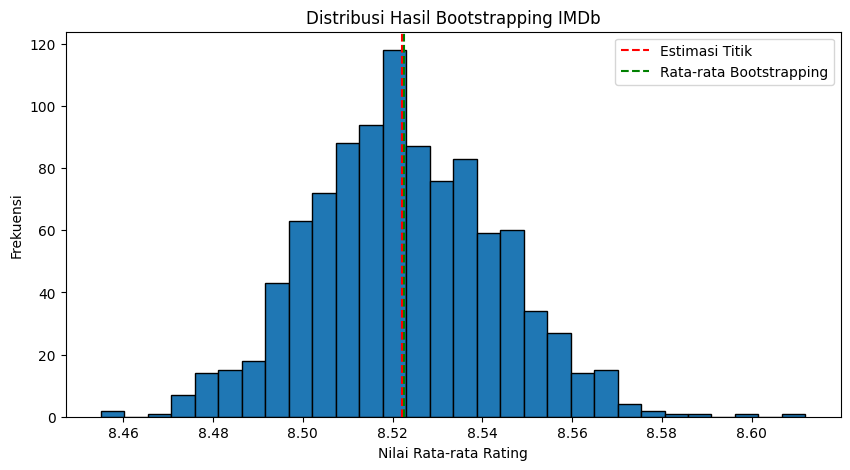

In [13]:
plt.figure(figsize=(10, 5))

plt.hist(
    bootstrap_results,
    bins=30,
    edgecolor='black'
)

plt.axvline(
    estimasi_titik,
    color='red',
    linestyle='--',
    label='Estimasi Titik'
)

plt.axvline(
    rata_bootstrap,
    color='green',
    linestyle='--',
    label='Rata-rata Bootstrapping'
)

plt.title('Distribusi Hasil Bootstrapping IMDb')
plt.xlabel('Nilai Rata-rata Rating')
plt.ylabel('Frekuensi')
plt.legend()
plt.show()

In [15]:
# Menyimpan data
data.to_csv('Data_IMDb_100_Sampel.csv', index=False)

# Menyimpan hasil perhitungan
hasil.to_csv('Hasil_Perhitungan_IMDb.csv', index=False)

# Menyimpan hasil resampling dengan pd.Series agar panjang kolom yang berbeda tidak menyebabkan error
resampling = pd.DataFrame({
    'Jackknife': pd.Series(jackknife_results),
    'Bootstrapping': pd.Series(bootstrap_results)
})

resampling.to_csv('Hasil_Resampling_IMDb.csv', index=False)

print("Semua hasil berhasil disimpan!")

Semua hasil berhasil disimpan!
